# Customer Sales Performance & Business Analytics Dashboard

Task 2 - Data Analysis with Python Internship

A beginner-to-intermediate project covering advanced Pandas, multi-table integration, feature engineering, business analytics and visualization.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
BASE=Path("..")
raw=pd.read_csv(BASE/"data/raw/public_retail_sales_sample.csv")
raw.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,10,2023-10-07,CUST010,Female,52,Clothing,4,50,200
1,11,2023-02-14,CUST011,Male,23,Clothing,2,50,100
2,12,2023-10-30,CUST012,Male,35,Beauty,3,25,75
3,13,2023-08-05,CUST013,Male,22,Electronics,3,500,1500
4,14,2023-01-17,CUST014,Male,64,Clothing,4,30,120


## 1. Data quality

In [2]:
print("Shape:",raw.shape)
print("Missing values:",int(raw.isna().sum().sum()))
print("Duplicate rows:",int(raw.duplicated().sum()))

Shape: (251, 9)
Missing values: 0
Duplicate rows: 0


In [3]:
df=raw.copy()
df.columns=[c.strip().lower().replace(" ","_") for c in df.columns]
df["date"]=pd.to_datetime(df["date"],errors="coerce")
for c in ["quantity","price_per_unit","total_amount"]: df[c]=pd.to_numeric(df[c],errors="coerce")
df["calculated_total"]=df["quantity"]*df["price_per_unit"]
df["amount_check"]=np.isclose(df["calculated_total"],df["total_amount"])
df=df.drop_duplicates()
df.head()

,transaction_id,date,customer_id,gender,age,product_category,quantity,price_per_unit,total_amount,calculated_total,amount_check
0,10,2023-10-07,CUST010,Female,52,Clothing,4,50,200,200,True
1,11,2023-02-14,CUST011,Male,23,Clothing,2,50,100,100,True
2,12,2023-10-30,CUST012,Male,35,Beauty,3,25,75,75,True
3,13,2023-08-05,CUST013,Male,22,Electronics,3,500,1500,1500,True
4,14,2023-01-17,CUST014,Male,64,Clothing,4,30,120,120,True


## 2. Create customer, product and sales tables

In [4]:
df["age_group"]=pd.cut(df["age"],[17,25,35,45,55,65],labels=["18-25","26-35","36-45","46-55","56-65"])
df["customer_segment"]=pd.cut(df["total_amount"],[-1,100,500,10000],labels=["Low Value","Mid Value","High Value"])
df["product_id"]="P_"+df["product_category"].str[:3].str.upper()+"_"+df["price_per_unit"].astype(int).astype(str)
customers=df[["customer_id","gender","age","age_group","customer_segment"]].drop_duplicates()
products=df.groupby(["product_id","product_category","price_per_unit"],as_index=False).size().rename(columns={"product_category":"category","price_per_unit":"standard_price","size":"transaction_count"})
sales=df[["transaction_id","date","customer_id","product_id","quantity","price_per_unit","total_amount"]]
print(customers.shape,products.shape,sales.shape)

(251, 5) (15, 4) (251, 7)


## 3. Merge

In [5]:
merged=sales.merge(customers,on="customer_id",how="left",validate="many_to_one").merge(products.drop(columns=["transaction_count"]),on="product_id",how="left",validate="many_to_one")
merged["month"]=merged["date"].dt.to_period("M").astype(str)
merged["quarter"]=merged["date"].dt.to_period("Q").astype(str)
merged["price_band"]=pd.cut(merged["price_per_unit"],[-1,50,150,10000],labels=["Budget","Standard","Premium"])
merged["revenue"]=merged["quantity"]*merged["price_per_unit"]
merged.head()

,transaction_id,date,customer_id,product_id,quantity,price_per_unit,total_amount,gender,age,age_group,customer_segment,category,standard_price,month,quarter,price_band,revenue
0,10,2023-10-07,CUST010,P_CLO_50,4,50,200,Female,52,46-55,Mid Value,Clothing,50,2023-10,2023Q4,Budget,200
1,11,2023-02-14,CUST011,P_CLO_50,2,50,100,Male,23,18-25,Low Value,Clothing,50,2023-02,2023Q1,Budget,100
2,12,2023-10-30,CUST012,P_BEA_25,3,25,75,Male,35,26-35,Low Value,Beauty,25,2023-10,2023Q4,Budget,75
3,13,2023-08-05,CUST013,P_ELE_500,3,500,1500,Male,22,18-25,High Value,Electronics,500,2023-08,2023Q3,Premium,1500
4,14,2023-01-17,CUST014,P_CLO_30,4,30,120,Male,64,56-65,Mid Value,Clothing,30,2023-01,2023Q1,Budget,120


## 4. KPIs and GroupBy

In [6]:
kpis=pd.Series({"Total Revenue":merged.total_amount.sum(),"Transactions":merged.transaction_id.nunique(),"Customers":merged.customer_id.nunique(),"Units Sold":merged.quantity.sum(),"Average Order Value":merged.total_amount.mean()})
kpis

Total Revenue          126430.000000
Transactions              251.000000
Customers                 251.000000
Units Sold                628.000000
Average Order Value       503.705179
dtype: float64

In [7]:
category_summary=merged.groupby("category",as_index=False).agg(revenue=("total_amount","sum"),units=("quantity","sum"),transactions=("transaction_id","nunique")).sort_values("revenue",ascending=False)
customer_ranking=merged.groupby(["customer_id","gender","age"],as_index=False).agg(revenue=("total_amount","sum"),units=("quantity","sum")).sort_values("revenue",ascending=False)
category_summary,customer_ranking.head(10)

(      category  revenue  units  transactions
 2  Electronics    44830    189            76
 1     Clothing    42240    236            94
 0       Beauty    39360    203            81,
     customer_id  gender  age  revenue  units
 5       CUST015  Female   42     2000      4
 55      CUST065    Male   51     2000      4
 62      CUST072  Female   20     2000      4
 79      CUST089  Female   55     2000      4
 99      CUST109  Female   34     2000      4
 114     CUST124    Male   33     2000      4
 108     CUST118  Female   30     2000      4
 64      CUST074  Female   18     2000      4
 83      CUST093  Female   35     2000      4
 147     CUST157    Male   62     2000      4)

## 5. Pivot table and cross-tab

In [8]:
pivot=pd.pivot_table(merged,index="age_group",columns="category",values="total_amount",aggfunc="sum",fill_value=0,observed=False)
cross_tab=pd.crosstab(merged["gender"],merged["category"])
pivot,cross_tab

(category   Beauty  Clothing  Electronics
 age_group                               
 18-25        6835     12085         8985
 26-35        7780     10270        10720
 36-45        9700      4885        11130
 46-55        9875      9595        10370
 56-65        5170      5405         3625,
 category  Beauty  Clothing  Electronics
 gender                                 
 Female        44        44           41
 Male          37        50           35)

## 6. Outlier detection

In [9]:
q1,q3=merged.total_amount.quantile([.25,.75]); iqr=q3-q1
lower,upper=q1-1.5*iqr,q3+1.5*iqr
outliers=merged[(merged.total_amount<lower)|(merged.total_amount>upper)]
print("Lower:",lower,"Upper:",upper,"Outliers:",len(outliers))
outliers.head()

Lower: -1200.0 Upper: 2160.0 Outliers: 0


,transaction_id,date,customer_id,product_id,quantity,price_per_unit,total_amount,gender,age,age_group,customer_segment,category,standard_price,month,quarter,price_band,revenue


## 7. Visualizations

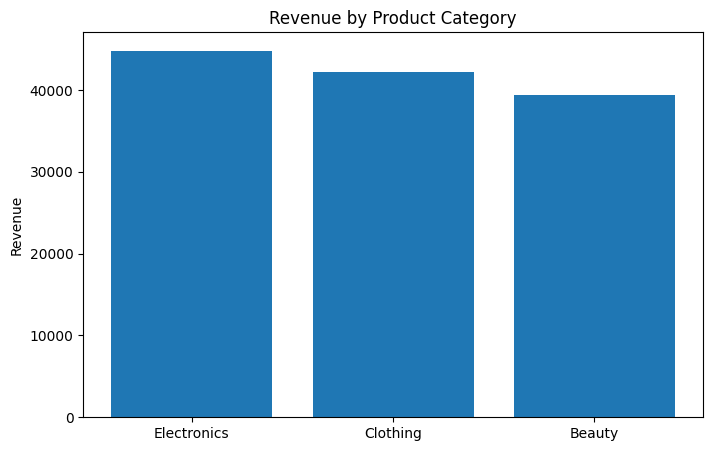

In [10]:
fig,ax=plt.subplots(figsize=(8,5))
ax.bar(category_summary.category,category_summary.revenue)
ax.set_title("Revenue by Product Category"); ax.set_ylabel("Revenue")
plt.show()

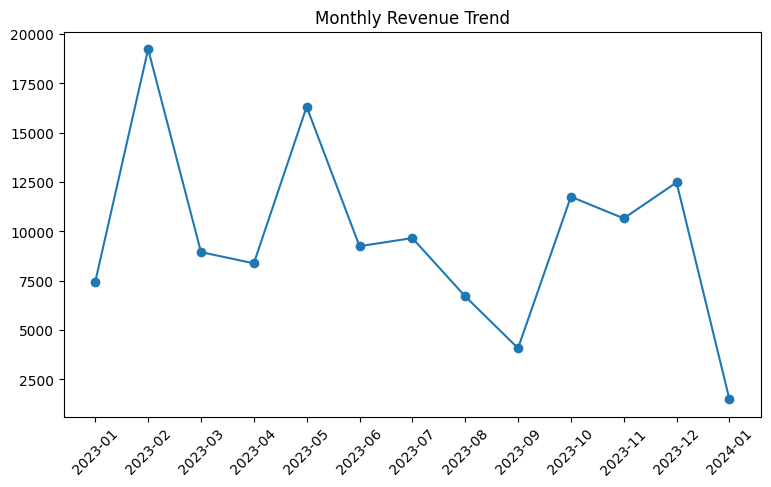

In [11]:
monthly=merged.groupby("month",as_index=False).total_amount.sum()
fig,ax=plt.subplots(figsize=(9,5)); ax.plot(monthly.month,monthly.total_amount,marker="o")
ax.set_title("Monthly Revenue Trend"); ax.tick_params(axis="x",rotation=45)
plt.show()

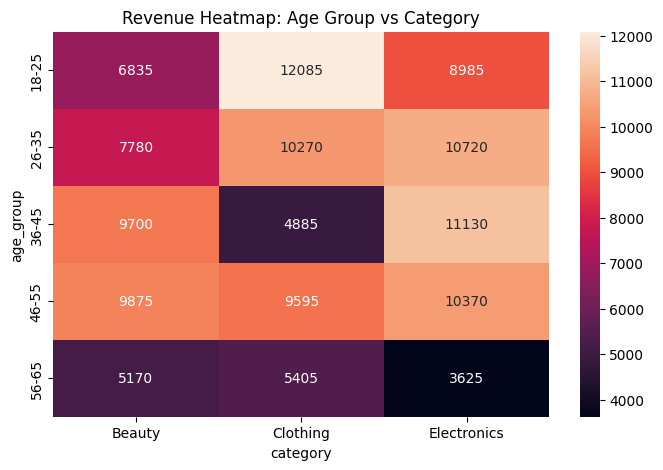

In [12]:
fig,ax=plt.subplots(figsize=(8,5)); sns.heatmap(pivot,annot=True,fmt=".0f",ax=ax)
ax.set_title("Revenue Heatmap: Age Group vs Category"); plt.show()

## 8. Notes

The source does not provide original product IDs, product costs or profit. Product IDs are engineered for this exercise and profit is not invented. The working sample is smaller than the full public file.